In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from tqdm import tqdm
import pickle
from pathlib import Path
import importlib
from glob import glob
import re

import Particles_2D
importlib.reload(Particles_2D)
from Particles_2D import Particles_2D
from Particles_2D import coldstart_finder
from Particles_2D import temperature_drop_production

In [28]:
density_paths = glob(r"density_runs/**/*.pkl",recursive=True)

In [37]:
density_cd = {}
density_eq = {}
density_prod = {}
for path in density_paths:
    with open(path,"rb") as f:
        run = pickle.load(f)
    density = run.N/(run.LENGTH)**2
    run = Particles_2D(R=run.con,density=density,N=1000,temperature=0.1)

    if "cold_start" in path:
        density_cd[density] = run
    elif "equilibrium" in path:
        density_eq[density] = run
    elif "production" in path:
        density_prod[density] = run


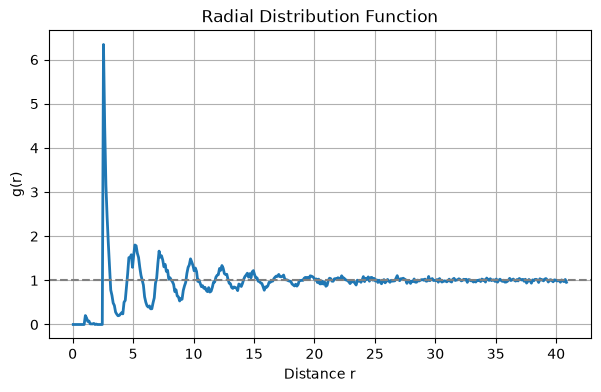

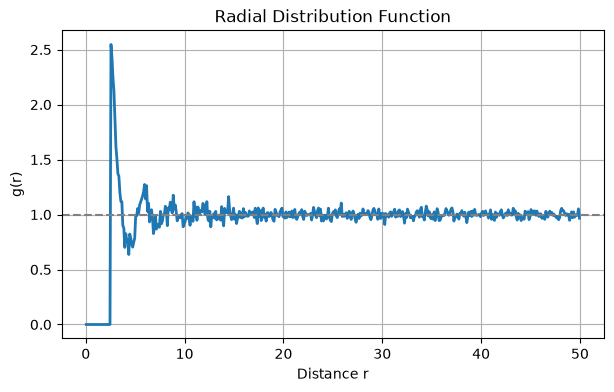

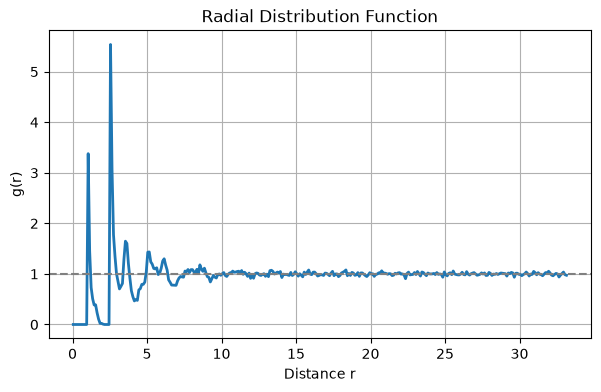

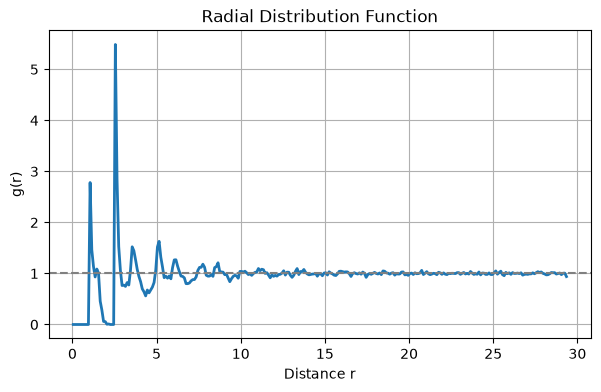

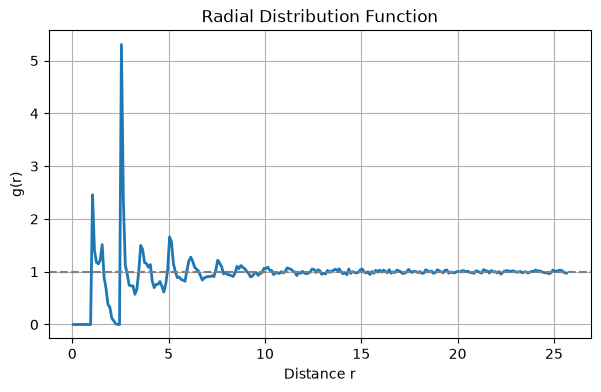

In [38]:
for run in list(density_prod.values()):
    run.radial_distribution()

In [48]:
density_prod.values()[]

SyntaxError: invalid syntax (2470218832.py, line 1)

In [63]:
with open(r"runs\production\prod_0.291_0.18_100.pkl","rb") as f:
    coldstart = pickle.load(f)
    R = coldstart.R

test = Particles_2D(R=R,density=0.291,N=100,temperature=0.1,delta_step=0.28)

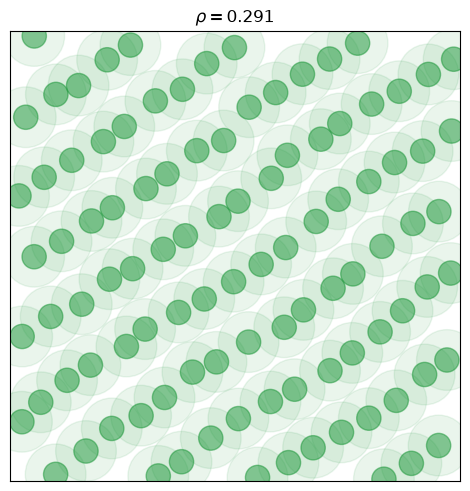

In [64]:
test.scatter()

In [17]:
test.run_mc(max_iter=2*(10**6),equilibrium=True)

100%|██████████| 2000000/2000000 [00:54<00:00, 36384.40it/s]


In [18]:
test.print_status()

Overlaps: 0
Energy: 108.0
Accepted movements: 609643
Completed iterations: 2000000
Acceptance ratio:0.3


System Parameters
Number of particles:100
Density*:0.291
Temperature*:0.1
Delta Step:0.28


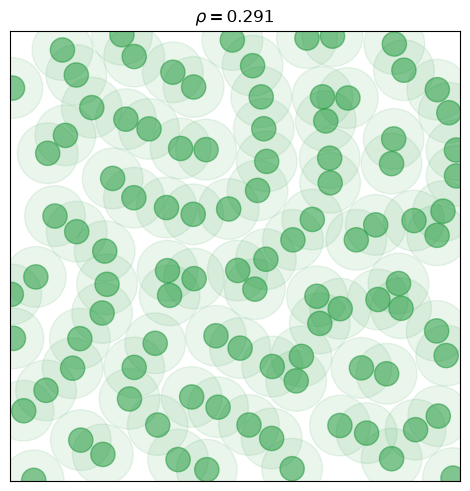

In [19]:
test.scatter()

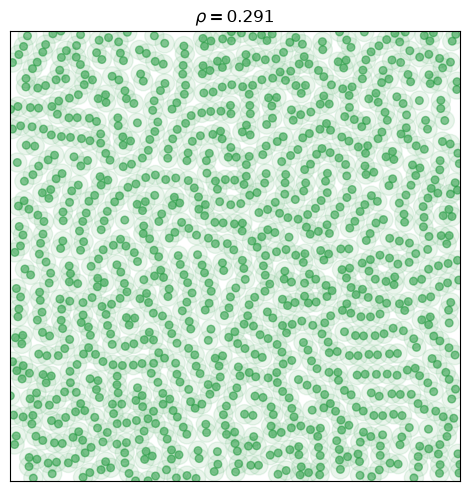

In [244]:
test.scatter()

In [277]:
test.energy

np.float64(1220.0)

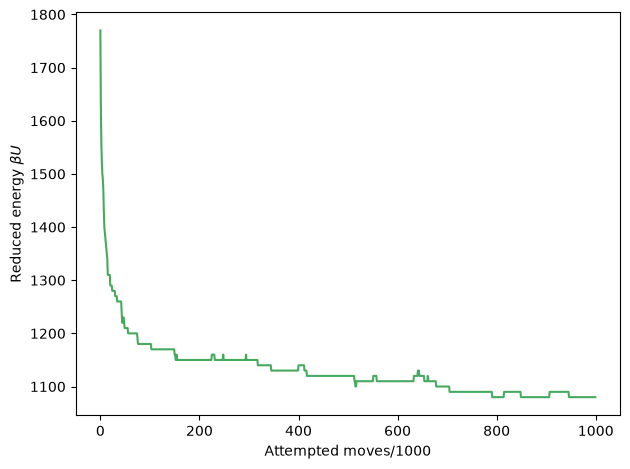

In [20]:
energy_equilibrium = -np.array(test.equilibrium_array)

fig, ax = plt.subplots()
ax.plot(energy_equilibrium, color="#189536cc", linewidth=1.5)

ax.set_xlabel("Attempted moves/1000")
ax.set_ylabel(r"Reduced energy $\beta U$")
plt.tight_layout()
plt.show()

In [188]:
with open(r"runs\equilibrium\equ_0.291_0.3_100.pkl","rb") as f:
    coldstart = pickle.load(f)
    R = coldstart.R

In [197]:
test.print_status()

Overlaps: 1230
Energy: inf
Accepted movements: 0
Completed iterations: 0
Acceptance ratio:0.0


System Parameters
Number of particles:100
Density*:0.1
Temperature*:0.1
Delta Step:0.4


In [114]:
coldstart.R[15]

array([16.00385638,  2.29504316])

In [175]:
test.LENGTH

np.float64(31.622776601683793)

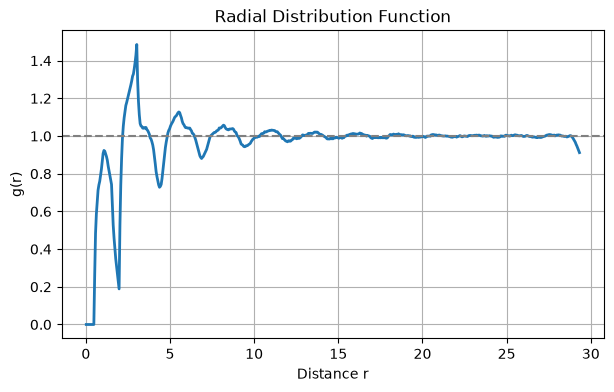

In [241]:
test.grr()

In [153]:
r2

array([], dtype=float64)

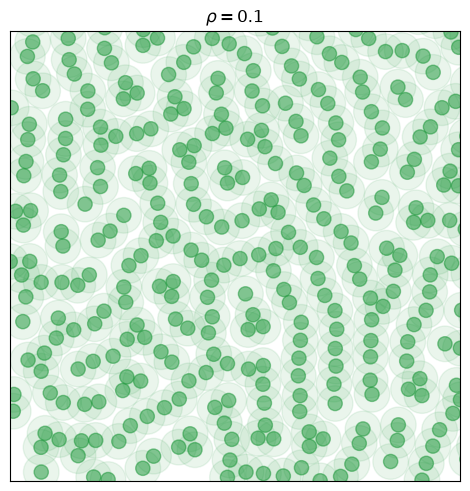

In [126]:
test.scatter()

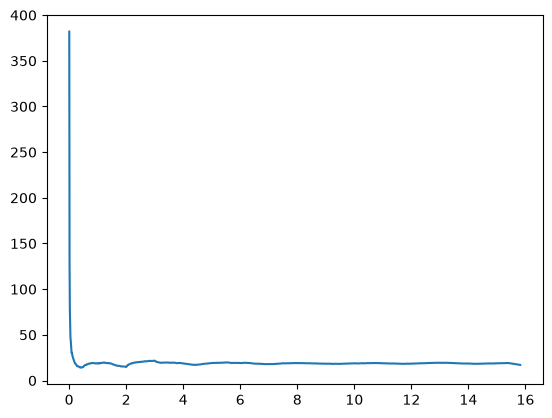

In [177]:
plt.plot(r_densities.keys(),r_densities.values())

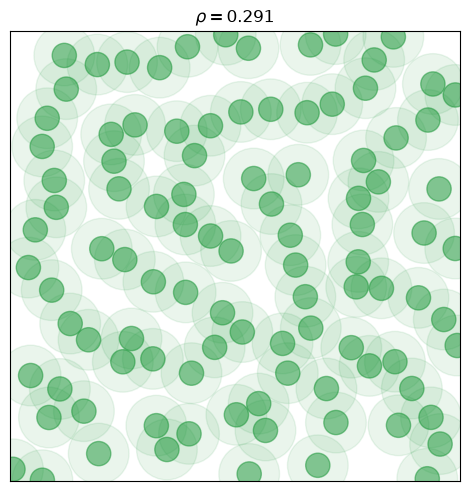

In [31]:
coldstart.scatter()

In [132]:
coldstart= Particles_2D(N=100,density=0.291,temperature=0.1,R=R,delta_step=0.4)

In [133]:
coldstart.run_mc(max_iter=2*(10**6),equilibrium=True,delta_optim=False)

100%|██████████| 2000000/2000000 [00:32<00:00, 62081.76it/s]


In [ ]:
len(coldstart.equilibrium_array)

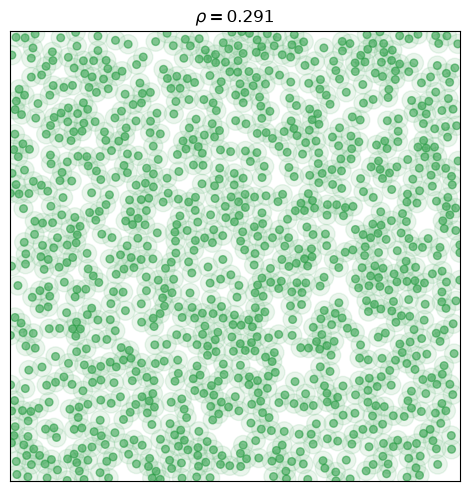

In [36]:
coldstart.scatter()

In [17]:
coldstart.print_status()

Overlaps: 0
Energy: inf
Accepted movements: 23320
Completed iterations: 47003
Acceptance ratio:0.5


System Parameters
Number of particles:1000
Density*:0.291
Temperature*:0.2
Delta Step:2


In [48]:
temp_drop_starter = Particles_2D(N=1000,temperature=0.25,density=0.291,R=R)

In [ ]:
temp_drop_starter.run_mc(max_iter=2*(10**8),equilibrium=False,production=True)

  0%|          | 0/200000000 [00:00<?, ?it/s]

 20%|█▉        | 39677703/200000000 [21:10<1:07:59, 39296.99it/s]

In [49]:
temp_drop_starter.print_status()

Overlaps: 0
Energy: 1407
Accepted movements: 854053
Completed iterations: 2000000
Acceptance ratio:0.43


System Parameters
Number of particles:1000
Density*:0.291
Temperature*:0.25
Delta Step:0.4


In [49]:
temp_drop_starter.print_status()

Overlaps: 0
Energy: 2537
Accepted movements: 0
Completed iterations: 0
Acceptance ratio:0.0


System Parameters
Number of particles:1000
Density*:0.291
Temperature*:0.25
Delta Step:0.4


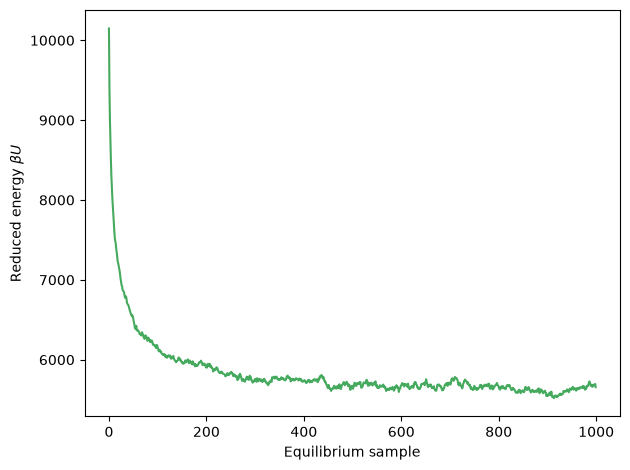

In [51]:

energy_equilibrium = -np.array(temp_drop_starter.equilibrium_array)

fig, ax = plt.subplots()
ax.plot(energy_equilibrium, color="#189536cc", linewidth=1.5)

ax.set_xlabel("Equilibrium sample")
ax.set_ylabel(r"Reduced energy $\beta U$")
plt.tight_layout()
plt.show()

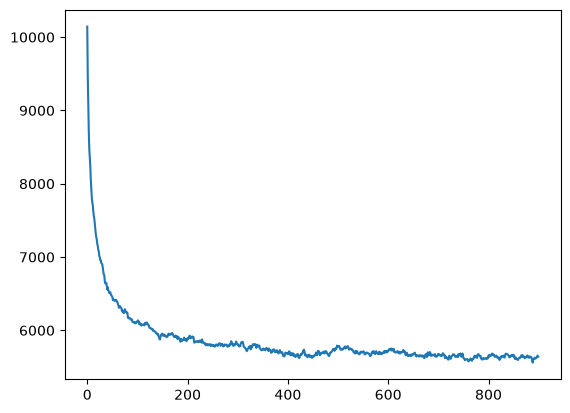

In [19]:
plt.plot(-np.array(temp_drop_starter.equilibrium_array)[:-100])

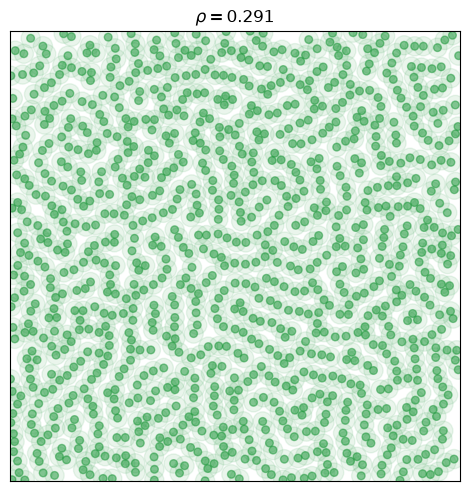

In [18]:
temp_drop_starter.scatter()

In [52]:
temp_drop_starter.state_snapshot()

In [53]:
temp_drop_starter.run_mc(production=True)

100%|██████████| 20000000/20000000 [44:20<00:00, 7516.41it/s] 


In [ ]:
(temp_drop_starter.energy_M2/(2*(10**7)-1))

np.float64(180572.15613776885)

In [38]:
temperature_drop_production(coldstart=R)



######################################################################
T* = 0.300 (1/10)
######################################################################


100%|██████████| 20000000/20000000 [08:24<00:00, 39671.43it/s]


TypeError: 'float' object cannot be interpreted as an integer

In [73]:
prod_runs = [x for x in glob(r"runs/production/*pkl") if "_1000.pkl" in x]
eq_runs = [x for x in glob(r"runs/equilibrium/*pkl") if "_1000.pkl" in x]

In [74]:
cv = {}
average = {}
prod = {}
eq = {}
for path in prod_runs:
    with open(path,"rb") as f:
        run = pickle.load(f)
    prod[run.temperature] = run
    average[run.temperature] = run.energy_mean
    cv[run.temperature] = run.energy_M2/((run.production_iterations-1)*run.temperature**2)

for path in eq_runs:
    with open(path,"rb") as f:
        run = pickle.load(f)
    eq[run.temperature] = run

In [76]:
cv = dict(sorted(cv.items(), key=lambda item: item[0]))

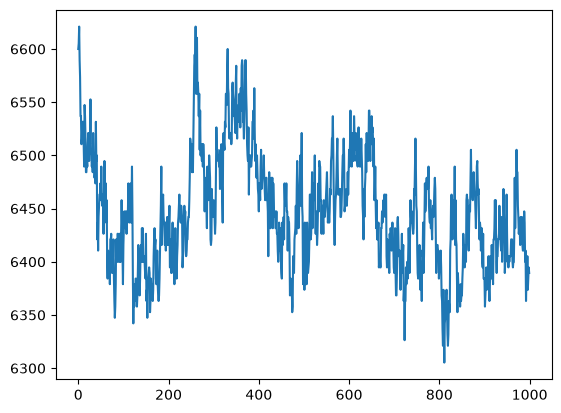

In [32]:
plt.plot(-np.array(eq[0.19].equilibrium_array))

In [20]:
eq.keys()

dict_keys([0.15, 0.16, 0.17, 0.18, 0.19, 0.225, 0.25, 0.275, 0.2, 0.3])

In [12]:
prod[0.3].energy_mean

np.float64(1520.2597798000702)

In [9]:
cv.keys()

dict_keys([0.15, 0.16, 0.17, 0.18, 0.19, 0.2, 0.225, 0.25, 0.275, 0.3])

Text(0.5, 0, '$T^*$')

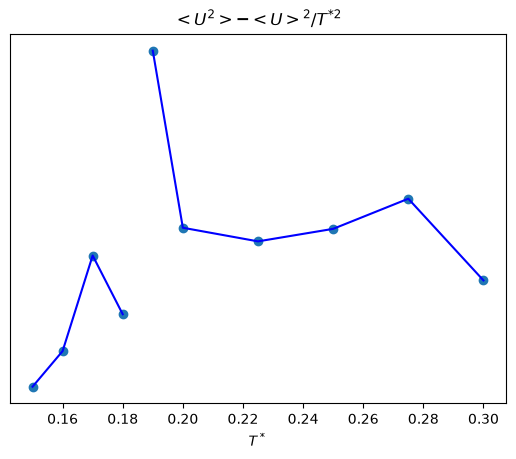

In [78]:
plt.scatter(cv.keys(),cv.values())
plt.plot(list(cv.keys())[:4],list(cv.values())[:4],color="blue")
plt.plot(list(cv.keys())[4:],list(cv.values())[4:],color="blue")
plt.yticks([])
plt.title("$<U^2>-<U>^2/T^{*2}$")
plt.xlabel("$T^*$")

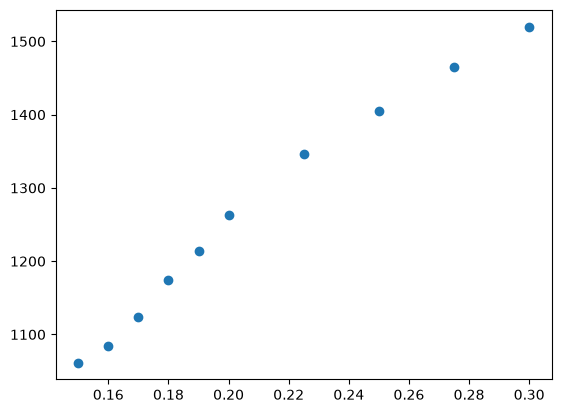

In [42]:
plt.scatter(average.keys(),average.values())

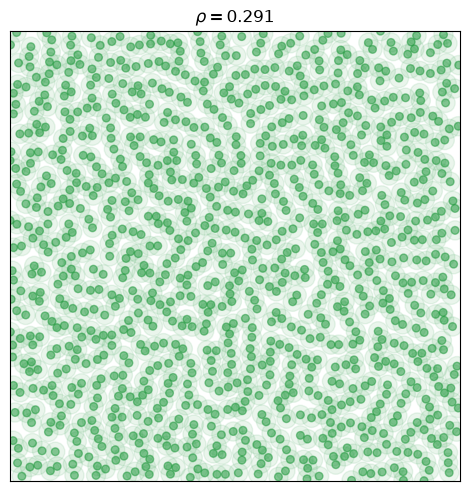

In [23]:
prod[0.30].scatter()

In [30]:
prod_runs = [x for x in glob(r"runs/production/*pkl") if "run_prod" in x]
eq_runs = [x for x in glob(r"runs/equilibrium/*pkl") if "run_equ" in x]

In [31]:
cv = {}
prod = {}
eq = {}
for path in prod_runs:
    with open(path,"rb") as f:
        sim = pickle.load(f)
    temperature = re.findall(r"(?:(0\.[0-9]*)\.pkl)",path)[0]
    var = (np.array(sim.block_averages)**2).mean()-(np.array(sim.block_averages).mean())**2
    cv[temperature] = var/(float(temperature)**2)

Text(0.5, 0, '$T^*$')

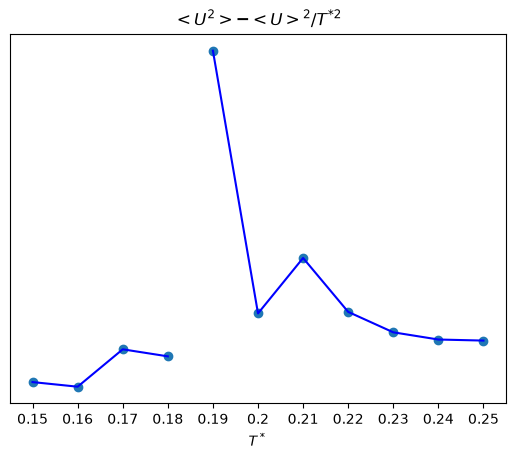

In [38]:
plt.plot(list(cv.keys())[:4],list(cv.values())[:4],color="blue")
plt.plot(list(cv.keys())[4:],list(cv.values())[4:],color="blue")
plt.scatter(list(cv.keys()),list(cv.values()))
plt.yticks([])
plt.title("$<U^2>-<U>^2/T^{*2}$")
plt.xlabel("$T^*$")